# Airfoil Data Processing Pipeline — Annotated Report

This notebook turns **825 raw XFOIL/airfoiltools-style JSON files** (each holding one airfoil's
surface coordinates and its XFOIL polar sweep — `Cl`, `Cd`, `Cm` vs `alpha`/`Re`/`Ncrit`) into three
progressively more refined, ML-ready datasets:

| Dataset | Grain | What it holds | Saved as |
|---|---|---|---|
| **A — Metadata** | 1 row per airfoil | Shape descriptors: max thickness %, max camber %, and where on the chord they occur | `processed/airfoil_metadata.csv` |
| **B — Aerodynamics** | 1 row per (airfoil, Re, alpha, Ncrit) | Every simulated flow condition and its resulting `Cl`, `Cd`, `Cm` | `processed/airfoil_aerodynamic_data.csv` |
| **C — ML dataset** | 1 row per (airfoil, Re, alpha, Ncrit) | Dataset B joined back to Dataset A's shape descriptors — geometry + flow conditions as inputs, aerodynamic coefficients as targets | `processed/airfoil_ml_dataset.csv` |

The notebook then closes with an exploratory data analysis (EDA) pass over Dataset C: distributions,
sanity checks, a single-airfoil case study, and a feature-correlation matrix — the standard checks
you'd want before handing this data to a model.

**Note:** this markdown commentary was added purely to document the existing notebook section by
section — no code cells, outputs, or logic below have been modified.

---
### Setup

In [1]:
%pip install pandas matplotlib numpy 

Note: you may need to restart the kernel to use updated packages.


## Part 1 — Locate and audit the raw JSON files

Before doing any real parsing, the notebook first does a **structural audit** of all 825 files:
does each one actually contain the expected keys (`xps`, `yps`, `xss`, `yss`, `polars`), and how many
polar (flow-condition) records does each contain? This catches malformed or incomplete files early,
before they can cause confusing errors deeper in the pipeline.

`DATA_PATH = Path("json")` — the JSON files are expected in a `json/` folder next to this notebook.

In [2]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = Path("json")

json_files = list(DATA_PATH.glob("*.json"))

print(f"Total JSON files found: {len(json_files)}")

Total JSON files found: 825


The loop below reads every file, wrapping the parse in a `try/except` so a single bad file can't
kill the whole batch — malformed files are simply recorded in `results` with an `error` message
instead of the expected fields, so they surface in `summary_df` rather than crashing the run.

In [3]:
results = []

for file_path in json_files:
    try:
        with open(file_path, "r", encoding="utf-8") as f:
            data = json.load(f)

        results.append({
            "file": file_path.name,
            "airfoil_name": data.get("name"),
            "has_polars": "polars" in data,
            "has_xps": "xps" in data,
            "has_yps": "yps" in data,
            "has_xss": "xss" in data,
            "has_yss": "yss" in data,
            "polar_count": len(data.get("polars", []))
        })

    except Exception as e:
        results.append({
            "file": file_path.name,
            "airfoil_name": None,
            "error": str(e)
        })

summary_df = pd.DataFrame(results)

summary_df.head()

,file,airfoil_name,has_polars,has_xps,has_yps,has_xss,has_yss,polar_count
0,2032c-il - 20-32C AIRFOIL.json,2032c-il - 20-32C AIRFOIL,True,True,True,True,True,678
1,a18-il - A18 (original).json,a18-il - A18 (original),True,True,True,True,True,775
2,a63a108c-il - NASA_AMES 63A108 MOD C AIRFOIL.json,a63a108c-il - NASA_AMES 63A108 MOD C AIRFOIL,True,True,True,True,True,814
3,ag04-il - AG04.json,ag04-il - AG04,True,True,True,True,True,752
4,ag09-il - AG09.json,ag09-il - AG09,True,True,True,True,True,635


A quick tally: how many of the 825 files actually have a `polars` block, how many have *all four*
geometry arrays present, and the total number of individual polar (flow-condition) records across
every file combined — this last number is roughly the upper bound on how many rows Dataset B can have.

In [4]:
print("Total files:", len(summary_df))

print("\nFiles with polars:")
print(summary_df["has_polars"].sum())

print("\nFiles with complete geometry:")

geometry_columns = [
    "has_xps",
    "has_yps",
    "has_xss",
    "has_yss"
]

print(summary_df[geometry_columns].all(axis=1).sum())

print("\nTotal polar records:")
print(summary_df["polar_count"].sum())

Total files: 825

Files with polars:
825

Files with complete geometry:
825

Total polar records:
768542


## Part 2 — Extract airfoil geometry → Dataset A

The file list is re-globbed with `sorted()` here (rather than the arbitrary OS order used in Part 1)
so that every airfoil gets a **stable, reproducible `airfoil_id`** — important since Datasets B and C
will later be joined back to Dataset A using this ID.

In [5]:
DATA_PATH = Path("json")

json_files = sorted(DATA_PATH.glob("*.json"))

print(f"Total JSON files: {len(json_files)}")

Total JSON files: 825


### Geometry feature extraction

`extract_geometry_features` turns raw pressure-side/suction-side coordinate arrays into standard
airfoil shape descriptors:

1. Sort both surfaces by `x` (defensive — some sources don't guarantee LE→TE order).
2. Find the **overlapping** x-range between the two surfaces and resample both onto 200 common
   chordwise stations via linear interpolation (`np.interp`), so thickness/camber can be compared
   point-by-point even if the original surfaces used different spacing.
3. At each station, take `y_upper = max(y_ps, y_ss)` and `y_lower = min(y_ps, y_ss)` — this determines
   which side is actually "upper" from the data itself, rather than assuming the pressure side is
   always below the suction side (a safe, format-agnostic choice).
4. **Thickness** = `y_upper - y_lower`; **camber** = the mean of the two surfaces at each station.
5. Report the *maximum* thickness and (absolute) camber, each as a percentage of chord, along with
   *where* on the chord (0–1) they occur — the classic `t/c` and camber descriptors used to
   characterize an airfoil family.

In [6]:
def extract_geometry_features(data):
    
    xps = np.array(data["xps"], dtype=float)
    yps = np.array(data["yps"], dtype=float)

    xss = np.array(data["xss"], dtype=float)
    yss = np.array(data["yss"], dtype=float)

    # Sort both surfaces by X coordinate
    ps_order = np.argsort(xps)
    ss_order = np.argsort(xss)

    xps = xps[ps_order]
    yps = yps[ps_order]

    xss = xss[ss_order]
    yss = yss[ss_order]

    # Find common X range
    x_min = max(xps.min(), xss.min())
    x_max = min(xps.max(), xss.max())

    # Create common chord positions
    x_common = np.linspace(x_min, x_max, 200)

    # Interpolate both surfaces
    y_ps = np.interp(x_common, xps, yps)
    y_ss = np.interp(x_common, xss, yss)

    # Determine upper and lower surface automatically
    y_upper = np.maximum(y_ps, y_ss)
    y_lower = np.minimum(y_ps, y_ss)

    # Thickness and camber
    thickness = y_upper - y_lower
    camber = (y_upper + y_lower) / 2

    # Chord
    chord_length = x_max - x_min

    # Maximum thickness
    max_thickness_index = np.argmax(thickness)

    max_thickness = thickness[max_thickness_index]
    max_thickness_position = x_common[max_thickness_index]

    # Maximum absolute camber
    max_camber_index = np.argmax(np.abs(camber))

    max_camber = camber[max_camber_index]
    max_camber_position = x_common[max_camber_index]

    return {
        "pressure_points": len(xps),
        "suction_points": len(xss),

        "chord_length": chord_length,

        "max_thickness": max_thickness,
        "max_thickness_percent": (
            max_thickness / chord_length * 100
        ),

        "max_thickness_position": (
            max_thickness_position / chord_length
        ),

        "max_camber": max_camber,
        "max_camber_percent": (
            abs(max_camber) / chord_length * 100
        ),

        "max_camber_position": (
            max_camber_position / chord_length
        )
    }

Loop over every airfoil file, compute its geometry features, and assemble one row per airfoil.
As in Part 1, parsing errors are caught and diverted into `failed_files` rather than stopping the batch.

In [7]:
metadata_rows = []
failed_files = []

for airfoil_id, file_path in enumerate(json_files):

    try:
        with open(file_path, "r", encoding="utf-8") as f:
            data = json.load(f)

        features = extract_geometry_features(data)

        row = {
            "airfoil_id": airfoil_id,
            "airfoil_name": data.get("name", file_path.stem),
            "source_file": file_path.name,
            **features
        }

        metadata_rows.append(row)

    except Exception as e:

        failed_files.append({
            "file": file_path.name,
            "error": str(e)
        })

print(f"Successfully processed: {len(metadata_rows)}")
print(f"Failed: {len(failed_files)}")

Successfully processed: 825
Failed: 0


In [8]:
metadata_df = pd.DataFrame(metadata_rows)

metadata_df.head()

,airfoil_id,airfoil_name,source_file,pressure_points,suction_points,chord_length,max_thickness,max_thickness_percent,max_thickness_position,max_camber,max_camber_percent,max_camber_position
0,0,2032c-il - 20-32C AIRFOIL,2032c-il - 20-32C AIRFOIL.json,100,100,1.0,0.079980,7.997990,0.180905,0.070024,7.002400,0.351759
1,1,a18-il - A18 (original),a18-il - A18 (original).json,100,100,1.0,0.073553,7.355300,0.291457,0.050369,5.036934,0.442211
2,2,a63a108c-il - NASA_AMES 63A108 MOD C AIRFOIL,a63a108c-il - NASA_AMES 63A108 MOD C AIRFOIL.json,100,100,1.0,0.077345,7.734461,0.301508,0.005516,0.551571,0.628141
3,3,ag04-il - AG04,ag04-il - AG04.json,100,100,1.0,0.064233,6.423280,0.221106,0.017525,1.752451,0.396985
4,4,ag09-il - AG09,ag09-il - AG09.json,100,100,1.0,0.048629,4.862922,0.180905,0.018584,1.858385,0.331658


Save **Dataset A** to `processed/airfoil_metadata.csv`.

In [9]:
OUTPUT_PATH = Path("processed")

OUTPUT_PATH.mkdir(parents=True, exist_ok=True)

metadata_df.to_csv(
    OUTPUT_PATH / "airfoil_metadata.csv",
    index=False
)

print("Dataset A saved successfully!")

Dataset A saved successfully!


### Quick look at Dataset A

`describe()` gives the spread of thickness/camber across all 825 airfoils — useful for spotting
outliers (e.g. an unrealistically thick or cambered section that might indicate a parsing issue).

In [10]:
metadata_df.describe()

,airfoil_id,pressure_points,suction_points,chord_length,max_thickness,max_thickness_percent,max_thickness_position,max_camber,max_camber_percent,max_camber_position
count,825.00000,825.0,825.0,825.0,825.000000,825.000000,825.000000,825.000000,825.000000,825.000000
mean,412.00000,100.0,100.0,1.0,0.123828,12.382817,0.313885,0.033712,3.404164,0.386508
std,238.30128,0.0,0.0,0.0,0.050388,5.038810,0.071746,0.023355,2.287060,0.178336
min,0.00000,100.0,100.0,1.0,0.019950,1.995000,0.030151,-0.045050,0.000000,0.000000
25%,206.00000,100.0,100.0,1.0,0.089998,8.999813,0.276382,0.017153,1.735546,0.301508
50%,412.00000,100.0,100.0,1.0,0.119506,11.950559,0.301508,0.031973,3.227173,0.402010
75%,618.00000,100.0,100.0,1.0,0.150006,15.000613,0.356784,0.047962,4.796248,0.487437
max,824.00000,100.0,100.0,1.0,0.664257,66.425674,0.597990,0.160343,16.034264,1.000000


In [11]:
metadata_df[
    [
        "airfoil_name",
        "max_thickness_percent",
        "max_camber_percent",
        "max_thickness_position",
        "max_camber_position"
    ]
].head(10)

,airfoil_name,max_thickness_percent,max_camber_percent,max_thickness_position,max_camber_position
0,2032c-il - 20-32C AIRFOIL,7.997990,7.002400,0.180905,0.351759
1,a18-il - A18 (original),7.355300,5.036934,0.291457,0.442211
2,a63a108c-il - NASA_AMES 63A108 MOD C AIRFOIL,7.734461,0.551571,0.301508,0.628141
3,ag04-il - AG04,6.423280,1.752451,0.221106,0.396985
4,ag09-il - AG09,4.862922,1.858385,0.180905,0.331658
5,ag11-il - AG11,5.811964,2.288086,0.256281,0.291457
6,ag13-il - AG13,5.834419,1.974811,0.211055,0.422111
7,ag16-il - AG16,7.114489,1.870530,0.231156,0.462312
8,ag18-il - AG18,5.867687,2.162357,0.211055,0.442211
9,ag24-il - AG24 Bubble Dancer DLG by Mark Drela,8.414245,2.215038,0.266332,0.457286


## Part 3 — Extract every aerodynamic data point → Dataset B

This section starts a fresh pass over the JSON files (re-globbed again), this time pulling out
**every single polar record** — i.e. every `(Re, alpha, Ncrit)` combination XFOIL was run at — rather
than just the geometry.

In [12]:
DATA_PATH = Path("json")

json_files = sorted(DATA_PATH.glob("*.json"))

print(f"Total JSON files found: {len(json_files)}")

Total JSON files found: 825


In [13]:
METADATA_PATH = Path("processed/airfoil_metadata.csv")

metadata_df = pd.read_csv(METADATA_PATH)

print("Dataset A loaded!")
print("Total airfoils:", len(metadata_df))

metadata_df.head()

Dataset A loaded!
Total airfoils: 825


,airfoil_id,airfoil_name,source_file,pressure_points,suction_points,chord_length,max_thickness,max_thickness_percent,max_thickness_position,max_camber,max_camber_percent,max_camber_position
0,0,2032c-il - 20-32C AIRFOIL,2032c-il - 20-32C AIRFOIL.json,100,100,1.0,0.079980,7.997990,0.180905,0.070024,7.002400,0.351759
1,1,a18-il - A18 (original),a18-il - A18 (original).json,100,100,1.0,0.073553,7.355300,0.291457,0.050369,5.036934,0.442211
2,2,a63a108c-il - NASA_AMES 63A108 MOD C AIRFOIL,a63a108c-il - NASA_AMES 63A108 MOD C AIRFOIL.json,100,100,1.0,0.077345,7.734461,0.301508,0.005516,0.551571,0.628141
3,3,ag04-il - AG04,ag04-il - AG04.json,100,100,1.0,0.064233,6.423280,0.221106,0.017525,1.752451,0.396985
4,4,ag09-il - AG09,ag09-il - AG09.json,100,100,1.0,0.048629,4.862922,0.180905,0.018584,1.858385,0.331658


Dataset A (already saved to CSV) is used to build a `file → airfoil_id` lookup, so that every row
extracted here gets the **same `airfoil_id`** Dataset A assigned to that airfoil — this is what makes
the later merge into Dataset C possible.

In [14]:
file_to_id = dict(
    zip(
        metadata_df["source_file"],
        metadata_df["airfoil_id"]
    )
)

print("Mappings created:", len(file_to_id))

Mappings created: 825


For each file, every entry in its `polars` list becomes one row: `Re`, `alpha`, `Ncrit`, and the
XFOIL outputs `Cl`, `Cd`, `Cdp`, `Cm`. The lift-to-drag ratio `Cl_Cd` is computed inline (guarding
against a zero or missing `Cd`), and rows missing the essential `Re`/`alpha` are skipped outright since
they can't be used downstream.

In [15]:
aero_rows = []

failed_files = []

for file_path in json_files:

    try:

        # Load JSON
        with open(file_path, "r", encoding="utf-8") as f:
            data = json.load(f)

        # Get airfoil ID
        airfoil_id = file_to_id.get(file_path.name)

        if airfoil_id is None:
            failed_files.append({
                "file": file_path.name,
                "error": "Airfoil ID not found in Dataset A"
            })

            continue

        airfoil_name = data.get(
            "name",
            file_path.stem
        )

        # Get polar records
        polars = data.get("polars", [])

        # Process every simulation result
        for polar in polars:

            Re = polar.get("Re")
            alpha = polar.get("alpha")
            Ncrit = polar.get("Ncrit")

            Cl = polar.get("Cl")
            Cd = polar.get("Cd")
            Cdp = polar.get("Cdp")
            Cm = polar.get("Cm")

            # Skip incomplete rows
            if Re is None or alpha is None:
                continue

            # Calculate Lift-to-Drag Ratio safely
            Cl_Cd = None

            if Cd is not None and Cd != 0 and Cl is not None:
                Cl_Cd = Cl / Cd

            aero_rows.append({

                "airfoil_id": airfoil_id,

                "airfoil_name": airfoil_name,

                "Re": Re,

                "alpha": alpha,

                "Ncrit": Ncrit,

                "Cl": Cl,

                "Cd": Cd,

                "Cdp": Cdp,

                "Cm": Cm,

                "Cl_Cd": Cl_Cd

            })

    except Exception as e:

        failed_files.append({
            "file": file_path.name,
            "error": str(e)
        })

In [16]:
aero_df = pd.DataFrame(aero_rows)

print("Total aerodynamic records:", len(aero_df))

print("Failed files:", len(failed_files))

aero_df.head()

Total aerodynamic records: 768542
Failed files: 0


,airfoil_id,airfoil_name,Re,alpha,Ncrit,Cl,Cd,Cdp,Cm,Cl_Cd
0,0,2032c-il - 20-32C AIRFOIL,200000.0,-8.75,9.0,-0.1581,0.09761,0.09467,-0.0262,-1.619711
1,0,2032c-il - 20-32C AIRFOIL,200000.0,-8.25,9.0,-0.2407,0.10671,0.10359,-0.0219,-2.255646
2,0,2032c-il - 20-32C AIRFOIL,200000.0,-8.00,9.0,-0.2303,0.10247,0.09935,-0.0213,-2.247487
3,0,2032c-il - 20-32C AIRFOIL,200000.0,-7.75,9.0,-0.2229,0.09947,0.09639,-0.0215,-2.240877
4,0,2032c-il - 20-32C AIRFOIL,200000.0,-6.75,9.0,-0.2314,0.09255,0.08980,-0.0166,-2.500270


### Cleaning Dataset B

Before trusting this data, the notebook checks for missing values per column, confirms the columns
actually came through as numeric dtypes (JSON parsing can sometimes leave numbers as Python objects),
and explicitly coerces the aerodynamic columns to numeric — any value that can't be converted becomes
`NaN` rather than silently breaking later arithmetic.

In [17]:
print(aero_df.isnull().sum())

airfoil_id      0
airfoil_name    0
Re              0
alpha           0
Ncrit           0
Cl              0
Cd              0
Cdp             0
Cm              0
Cl_Cd           0
dtype: int64


In [18]:
print(aero_df.dtypes)

airfoil_id        int64
airfoil_name     object
Re              float64
alpha           float64
Ncrit           float64
Cl              float64
Cd              float64
Cdp             float64
Cm              float64
Cl_Cd           float64
dtype: object


In [19]:
numeric_columns = [
    "Re",
    "alpha",
    "Ncrit",
    "Cl",
    "Cd",
    "Cdp",
    "Cm",
    "Cl_Cd"
]

for column in numeric_columns:

    aero_df[column] = pd.to_numeric(
        aero_df[column],
        errors="coerce"
    )

Rows missing any of the core fields (`Re`, `alpha`, `Cl`, `Cd`) are dropped — these are unusable for
aerodynamic analysis regardless of what else they contain.

In [20]:
aero_df_clean = aero_df.dropna(
    subset=[
        "Re",
        "alpha",
        "Cl",
        "Cd"
    ]
).copy()

print("Records before cleaning:", len(aero_df))
print("Records after cleaning:", len(aero_df_clean))

Records before cleaning: 768542
Records after cleaning: 768542


### Feature engineering on Dataset B

Two derived columns are added to make the data easier to model and plot later:
- **`abs_alpha`** — the unsigned angle of attack (handy for symmetry-related patterns).
- **`log_Re`** — Reynolds numbers here span orders of magnitude (5×10⁴ to 5×10⁶), so a log scale is
  far more useful for both plotting and as a model input than the raw value.

`Cl_Cd` is also recomputed at this point now that the data has been cleaned, so it's consistent with
the final, de-NaN'd rows.

In [21]:
aero_df_clean["abs_alpha"] = (
    aero_df_clean["alpha"].abs()
)

In [22]:
aero_df_clean["log_Re"] = np.log10(
    aero_df_clean["Re"]
)

In [23]:
aero_df_clean["Cl_Cd"] = (
    aero_df_clean["Cl"]
    /
    aero_df_clean["Cd"]
)

Save the cleaned, feature-engineered result as **Dataset B**: `processed/airfoil_aerodynamic_data.csv`.

In [24]:
OUTPUT_PATH = Path("processed")

OUTPUT_PATH.mkdir(
    parents=True,
    exist_ok=True
)

OUTPUT_FILE = (
    OUTPUT_PATH
    /
    "airfoil_aerodynamic_data.csv"
)

aero_df_clean.to_csv(
    OUTPUT_FILE,
    index=False
)

print("Dataset B saved!")
print("Location:", OUTPUT_FILE)

Dataset B saved!
Location: processed\airfoil_aerodynamic_data.csv


A coverage summary: how many distinct airfoils and Reynolds numbers are represented, and the full
angle-of-attack range swept — a sanity check that the dataset actually covers a broad range of
conditions before it's used for anything downstream.

In [25]:
print("Total records:", len(aero_df_clean))

print("\nUnique airfoils:")
print(aero_df_clean["airfoil_id"].nunique())

print("\nUnique Reynolds Numbers:")
print(sorted(aero_df_clean["Re"].unique()))

print("\nAlpha range:")
print(
    aero_df_clean["alpha"].min(),
    "to",
    aero_df_clean["alpha"].max()
)

print("\nColumns:")
print(aero_df_clean.columns.tolist())

Total records: 768542

Unique airfoils:
818

Unique Reynolds Numbers:
[np.float64(50000.0), np.float64(100000.0), np.float64(200000.0), np.float64(231000.0), np.float64(500000.0), np.float64(1000000.0), np.float64(2000000.0), np.float64(5000000.0)]

Alpha range:
-19.75 to 24.25

Columns:
['airfoil_id', 'airfoil_name', 'Re', 'alpha', 'Ncrit', 'Cl', 'Cd', 'Cdp', 'Cm', 'Cl_Cd', 'abs_alpha', 'log_Re']


## Part 4 — Merge geometry + aerodynamics into the final ML dataset (Dataset C)

Both saved CSVs are reloaded independently here (rather than reusing the in-memory DataFrames from
earlier), which makes this section runnable on its own without re-executing the whole notebook from
the top.

In [26]:
DATA_PATH = Path("processed")

metadata_df = pd.read_csv(
    DATA_PATH / "airfoil_metadata.csv"
)

aero_df = pd.read_csv(
    DATA_PATH / "airfoil_aerodynamic_data.csv"
)

print("Dataset A shape:", metadata_df.shape)
print("Dataset B shape:", aero_df.shape)

Dataset A shape: (825, 12)
Dataset B shape: (768542, 12)


In [27]:
print(metadata_df.columns.tolist())
print(aero_df.columns.tolist())

['airfoil_id', 'airfoil_name', 'source_file', 'pressure_points', 'suction_points', 'chord_length', 'max_thickness', 'max_thickness_percent', 'max_thickness_position', 'max_camber', 'max_camber_percent', 'max_camber_position']
['airfoil_id', 'airfoil_name', 'Re', 'alpha', 'Ncrit', 'Cl', 'Cd', 'Cdp', 'Cm', 'Cl_Cd', 'abs_alpha', 'log_Re']


Dataset B (aerodynamics, long format) is joined to Dataset A (geometry, one row per airfoil) on
`airfoil_id` with an **inner join** — every flow-condition row now also carries that airfoil's shape
descriptors.

In [28]:
ml_df = aero_df.merge(
    metadata_df,
    on="airfoil_id",
    how="inner",
    suffixes=("", "_geometry")
)

print("Final Dataset C shape:", ml_df.shape)

ml_df.head()

Final Dataset C shape: (768542, 23)


,airfoil_id,airfoil_name,Re,alpha,Ncrit,Cl,Cd,Cdp,Cm,Cl_Cd,...,source_file,pressure_points,suction_points,chord_length,max_thickness,max_thickness_percent,max_thickness_position,max_camber,max_camber_percent,max_camber_position
0,0,2032c-il - 20-32C AIRFOIL,200000.0,-8.75,9.0,-0.1581,0.09761,0.09467,-0.0262,-1.619711,...,2032c-il - 20-32C AIRFOIL.json,100,100,1.0,0.07998,7.99799,0.180905,0.070024,7.0024,0.351759
1,0,2032c-il - 20-32C AIRFOIL,200000.0,-8.25,9.0,-0.2407,0.10671,0.10359,-0.0219,-2.255646,...,2032c-il - 20-32C AIRFOIL.json,100,100,1.0,0.07998,7.99799,0.180905,0.070024,7.0024,0.351759
2,0,2032c-il - 20-32C AIRFOIL,200000.0,-8.00,9.0,-0.2303,0.10247,0.09935,-0.0213,-2.247487,...,2032c-il - 20-32C AIRFOIL.json,100,100,1.0,0.07998,7.99799,0.180905,0.070024,7.0024,0.351759
3,0,2032c-il - 20-32C AIRFOIL,200000.0,-7.75,9.0,-0.2229,0.09947,0.09639,-0.0215,-2.240877,...,2032c-il - 20-32C AIRFOIL.json,100,100,1.0,0.07998,7.99799,0.180905,0.070024,7.0024,0.351759
4,0,2032c-il - 20-32C AIRFOIL,200000.0,-6.75,9.0,-0.2314,0.09255,0.08980,-0.0166,-2.500270,...,2032c-il - 20-32C AIRFOIL.json,100,100,1.0,0.07998,7.99799,0.180905,0.070024,7.0024,0.351759


### Selecting the final modeling schema

The merged table is trimmed down to exactly the columns a supervised model would use:
- **Identity:** `airfoil_id` (kept for grouping/traceability, not as a model feature)
- **Geometry inputs:** `max_thickness_percent`, `max_thickness_position`, `max_camber_percent`, `max_camber_position`
- **Flow-condition inputs:** `Re`, `log_Re`, `alpha`, `Ncrit`
- **Targets:** `Cl`, `Cd`, `Cm`

This is the natural "given a shape and a flow condition, predict the aerodynamic response" framing.

In [29]:
ml_columns = [

    # Identity
    "airfoil_id",

    # Geometry features
    "max_thickness_percent",
    "max_thickness_position",
    "max_camber_percent",
    "max_camber_position",

    # Flow conditions
    "Re",
    "log_Re",
    "alpha",
    "Ncrit",

    # Targets
    "Cl",
    "Cd",
    "Cm"
]

ml_dataset = ml_df[ml_columns].copy()

ml_dataset.head()

,airfoil_id,max_thickness_percent,max_thickness_position,max_camber_percent,max_camber_position,Re,log_Re,alpha,Ncrit,Cl,Cd,Cm
0,0,7.99799,0.180905,7.0024,0.351759,200000.0,5.30103,-8.75,9.0,-0.1581,0.09761,-0.0262
1,0,7.99799,0.180905,7.0024,0.351759,200000.0,5.30103,-8.25,9.0,-0.2407,0.10671,-0.0219
2,0,7.99799,0.180905,7.0024,0.351759,200000.0,5.30103,-8.00,9.0,-0.2303,0.10247,-0.0213
3,0,7.99799,0.180905,7.0024,0.351759,200000.0,5.30103,-7.75,9.0,-0.2229,0.09947,-0.0215
4,0,7.99799,0.180905,7.0024,0.351759,200000.0,5.30103,-6.75,9.0,-0.2314,0.09255,-0.0166


Any `inf`/`-inf` that could have crept in from earlier ratio calculations is converted to `NaN` so
it can be handled uniformly, and the remaining missing-value counts are checked column by column.

In [30]:
ml_dataset.replace(
    [np.inf, -np.inf],
    np.nan,
    inplace=True
)

print("Missing values:")
print(ml_dataset.isnull().sum())

Missing values:
airfoil_id                0
max_thickness_percent     0
max_thickness_position    0
max_camber_percent        0
max_camber_position       0
Re                        0
log_Re                    0
alpha                     0
Ncrit                     0
Cl                        0
Cd                        0
Cm                        0
dtype: int64


Rows still missing any required geometry or aerodynamic value are dropped, leaving only complete,
usable records for modeling.

In [31]:
ml_dataset = ml_dataset.dropna(
    subset=[
        "max_thickness_percent",
        "max_camber_percent",
        "Re",
        "alpha",
        "Cl",
        "Cd"
    ]
)

print("Final usable records:", len(ml_dataset))

Final usable records: 768542


Save the final modeling table as **Dataset C**: `processed/airfoil_ml_dataset.csv`.

In [32]:
OUTPUT_FILE = (
    DATA_PATH /
    "airfoil_ml_dataset.csv"
)

ml_dataset.to_csv(
    OUTPUT_FILE,
    index=False
)

print("Dataset C saved successfully!")
print("Location:", OUTPUT_FILE)

Dataset C saved successfully!
Location: processed\airfoil_ml_dataset.csv


In [33]:
print("Dataset Shape:")
print(ml_dataset.shape)

print("\nNumber of Airfoils:")
print(ml_dataset["airfoil_id"].nunique())

print("\nDataset Statistics:")
display(ml_dataset.describe())

Dataset Shape:
(768542, 12)

Number of Airfoils:
818

Dataset Statistics:


,airfoil_id,max_thickness_percent,max_thickness_position,max_camber_percent,max_camber_position,Re,log_Re,alpha,Ncrit,Cl,Cd,Cm
count,768542.000000,768542.000000,768542.000000,768542.000000,768542.000000,7.685420e+05,768542.000000,768542.000000,768542.000000,768542.000000,768542.000000,768542.000000
mean,412.825981,12.999986,0.314427,3.325536,0.384019,4.033312e+05,5.384072,2.087603,6.861444,0.443995,0.035394,-0.052464
std,236.816382,5.091336,0.070443,2.276239,0.183648,3.794093e+05,0.467046,8.345368,2.018692,0.752716,0.030334,0.050835
min,0.000000,1.995000,0.030151,0.000000,0.000000,5.000000e+04,4.698970,-19.750000,0.000000,-2.289900,0.002650,-0.501000
25%,206.000000,9.816855,0.276382,1.666659,0.301508,1.000000e+05,5.000000,-4.500000,5.000000,-0.183600,0.013840,-0.083400
50%,420.000000,12.177814,0.301508,3.087229,0.402010,2.000000e+05,5.301030,2.000000,5.000000,0.516600,0.023970,-0.046700
75%,616.000000,15.646277,0.356784,4.697293,0.492462,5.000000e+05,5.698970,8.750000,9.000000,1.095100,0.047020,-0.015600
max,824.000000,66.425674,0.597990,16.034264,1.000000,5.000000e+06,6.698970,24.250000,9.000000,2.511300,0.591880,0.278000


## Part 5 — Exploratory Data Analysis on Dataset C

Dataset C is reloaded fresh from disk to begin an independent EDA pass — the standard set of checks
before handing data to a model: shape, types, missing values, duplicates, distributions, a physical
sanity check, a single-case study, and feature correlations.

In [34]:
df = pd.read_csv(
    DATA_PATH / "airfoil_ml_dataset.csv"
)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (768542, 12)


,airfoil_id,max_thickness_percent,max_thickness_position,max_camber_percent,max_camber_position,Re,log_Re,alpha,Ncrit,Cl,Cd,Cm
0,0,7.99799,0.180905,7.0024,0.351759,200000.0,5.30103,-8.75,9.0,-0.1581,0.09761,-0.0262
1,0,7.99799,0.180905,7.0024,0.351759,200000.0,5.30103,-8.25,9.0,-0.2407,0.10671,-0.0219
2,0,7.99799,0.180905,7.0024,0.351759,200000.0,5.30103,-8.00,9.0,-0.2303,0.10247,-0.0213
3,0,7.99799,0.180905,7.0024,0.351759,200000.0,5.30103,-7.75,9.0,-0.2229,0.09947,-0.0215
4,0,7.99799,0.180905,7.0024,0.351759,200000.0,5.30103,-6.75,9.0,-0.2314,0.09255,-0.0166


In [35]:
print("Total records:", len(df))
print("Total airfoils:", df["airfoil_id"].nunique())

print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

Total records: 768542
Total airfoils: 818

Columns:
['airfoil_id', 'max_thickness_percent', 'max_thickness_position', 'max_camber_percent', 'max_camber_position', 'Re', 'log_Re', 'alpha', 'Ncrit', 'Cl', 'Cd', 'Cm']

Data types:
airfoil_id                  int64
max_thickness_percent     float64
max_thickness_position    float64
max_camber_percent        float64
max_camber_position       float64
Re                        float64
log_Re                    float64
alpha                     float64
Ncrit                     float64
Cl                        float64
Cd                        float64
Cm                        float64
dtype: object

Missing values:
airfoil_id                0
max_thickness_percent     0
max_thickness_position    0
max_camber_percent        0
max_camber_position       0
Re                        0
log_Re                    0
alpha                     0
Ncrit                     0
Cl                        0
Cd                        0
Cm                       

### Duplicate checks

Two different notions of "duplicate" are checked: exact duplicate rows across *every* column, and
duplicate *simulation conditions* (same airfoil, `Re`, `alpha`, `Ncrit` combination) — the latter
would indicate the same physical run was recorded more than once, which matters more for modeling
than incidental duplicate rows would.

In [36]:
duplicates = df.duplicated().sum()

print("Duplicate rows:", duplicates)

Duplicate rows: 0


In [37]:
duplicate_conditions = df.duplicated(
    subset=[
        "airfoil_id",
        "Re",
        "alpha",
        "Ncrit"
    ]
).sum()

print("Duplicate simulation conditions:", duplicate_conditions)

Duplicate simulation conditions: 0


In [38]:
df.describe()

,airfoil_id,max_thickness_percent,max_thickness_position,max_camber_percent,max_camber_position,Re,log_Re,alpha,Ncrit,Cl,Cd,Cm
count,768542.000000,768542.000000,768542.000000,768542.000000,768542.000000,7.685420e+05,768542.000000,768542.000000,768542.000000,768542.000000,768542.000000,768542.000000
mean,412.825981,12.999986,0.314427,3.325536,0.384019,4.033312e+05,5.384072,2.087603,6.861444,0.443995,0.035394,-0.052464
std,236.816382,5.091336,0.070443,2.276239,0.183648,3.794093e+05,0.467046,8.345368,2.018692,0.752716,0.030334,0.050835
min,0.000000,1.995000,0.030151,0.000000,0.000000,5.000000e+04,4.698970,-19.750000,0.000000,-2.289900,0.002650,-0.501000
25%,206.000000,9.816855,0.276382,1.666659,0.301508,1.000000e+05,5.000000,-4.500000,5.000000,-0.183600,0.013840,-0.083400
50%,420.000000,12.177814,0.301508,3.087229,0.402010,2.000000e+05,5.301030,2.000000,5.000000,0.516600,0.023970,-0.046700
75%,616.000000,15.646277,0.356784,4.697293,0.492462,5.000000e+05,5.698970,8.750000,9.000000,1.095100,0.047020,-0.015600
max,824.000000,66.425674,0.597990,16.034264,1.000000,5.000000e+06,6.698970,24.250000,9.000000,2.511300,0.591880,0.278000


### Distribution checks

Histograms of the four key variables — `log_Re`, `alpha`, `Cl`, and `Cd` — reveal how well the sweep
covers the design space and whether any target variable is heavily skewed or has suspicious outliers
before it's used for training.

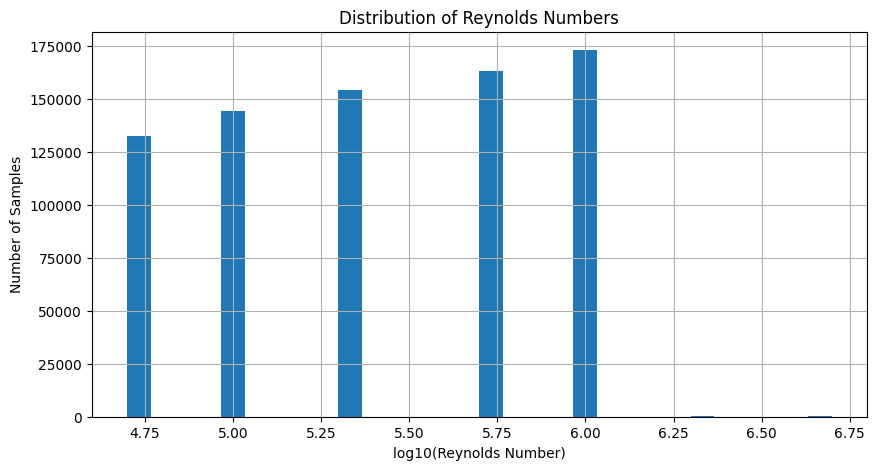

In [39]:
plt.figure(figsize=(10, 5))

plt.hist(df["log_Re"], bins=30)

plt.xlabel("log10(Reynolds Number)")
plt.ylabel("Number of Samples")

plt.title("Distribution of Reynolds Numbers")

plt.grid(True)

plt.show()

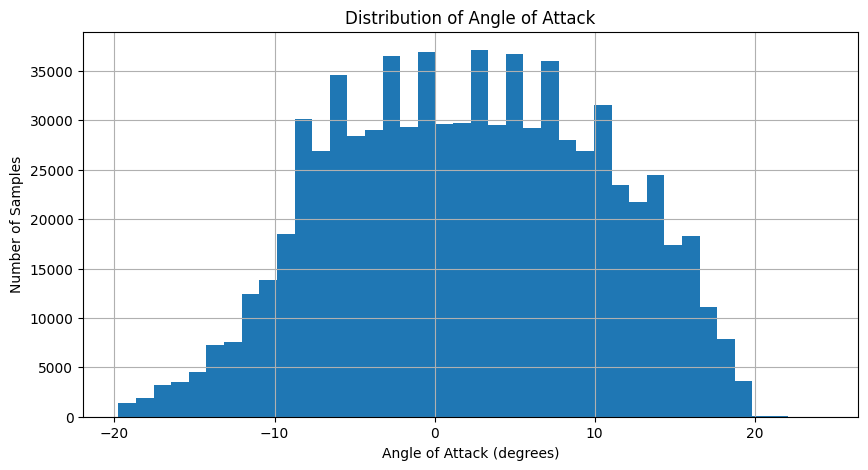

In [40]:
plt.figure(figsize=(10, 5))

plt.hist(df["alpha"], bins=40)

plt.xlabel("Angle of Attack (degrees)")
plt.ylabel("Number of Samples")

plt.title("Distribution of Angle of Attack")

plt.grid(True)

plt.show()

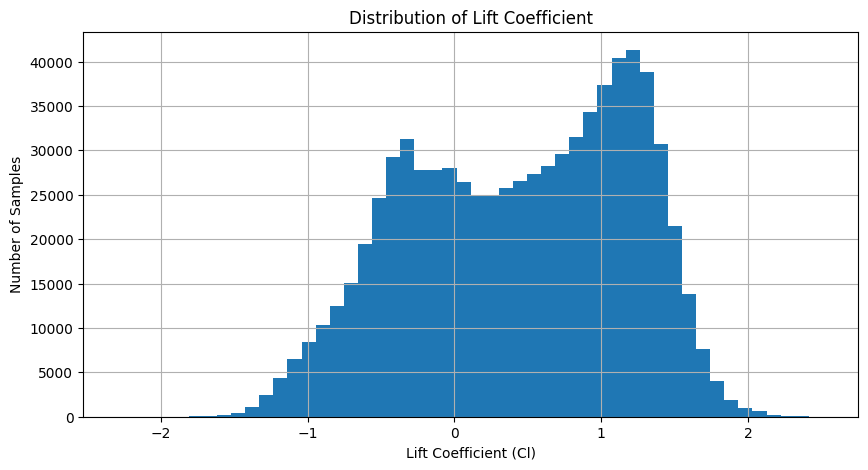

In [41]:
plt.figure(figsize=(10, 5))

plt.hist(df["Cl"], bins=50)

plt.xlabel("Lift Coefficient (Cl)")
plt.ylabel("Number of Samples")

plt.title("Distribution of Lift Coefficient")

plt.grid(True)

plt.show()

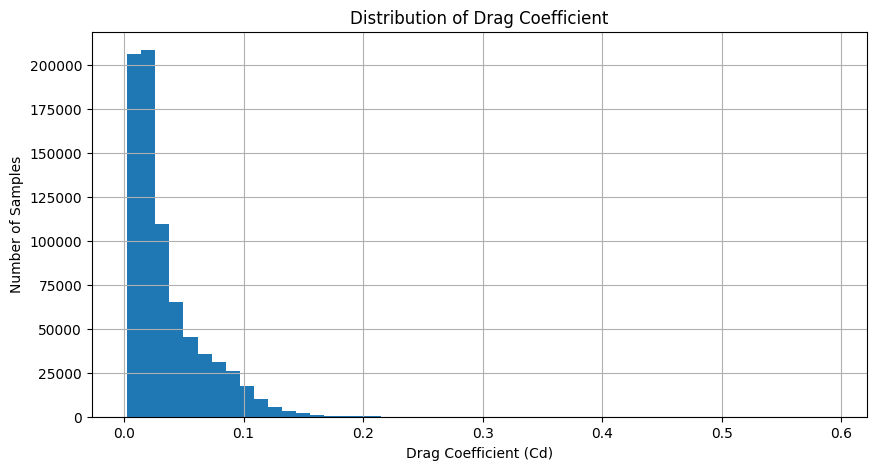

In [42]:
plt.figure(figsize=(10, 5))

plt.hist(df["Cd"], bins=50)

plt.xlabel("Drag Coefficient (Cd)")
plt.ylabel("Number of Samples")

plt.title("Distribution of Drag Coefficient")

plt.grid(True)

plt.show()

### Physical sanity check on drag

Drag coefficient `Cd` should, physically, always be **positive** — a negative value would indicate a
parsing artifact or a non-converged XFOIL run that slipped through earlier cleaning. This checks the
observed min/max and counts how many (if any) negative values remain.

In [43]:
print("Minimum Cd:", df["Cd"].min())
print("Maximum Cd:", df["Cd"].max())

print("\nNegative Cd values:")
print((df["Cd"] < 0).sum())

Minimum Cd: 0.00265
Maximum Cd: 0.59188

Negative Cd values:
0


### Case study: one airfoil's polar curve

To visually confirm the data behaves the way real aerodynamics should, one airfoil is picked (the
first `airfoil_id` in the dataset) at one specific Reynolds number, sorted by `alpha` — this isolates
a single classic "polar sweep" out of the combined dataset.

In [44]:
sample_airfoil = df["airfoil_id"].iloc[0]

sample = df[
    df["airfoil_id"] == sample_airfoil
]

sample_Re = sample["Re"].iloc[0]

sample = sample[
    sample["Re"] == sample_Re
].sort_values("alpha")

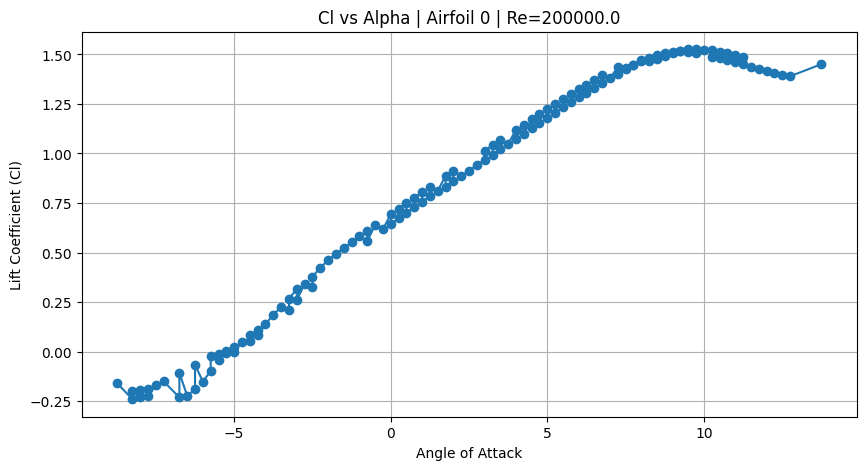

In [45]:
plt.figure(figsize=(10, 5))

plt.plot(
    sample["alpha"],
    sample["Cl"],
    marker="o"
)

plt.xlabel("Angle of Attack")
plt.ylabel("Lift Coefficient (Cl)")

plt.title(
    f"Cl vs Alpha | Airfoil {sample_airfoil} | Re={sample_Re}"
)

plt.grid(True)

plt.show()

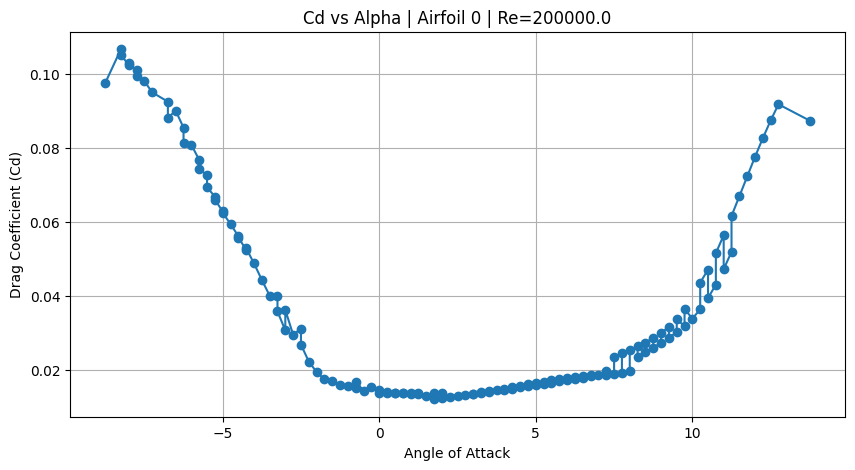

In [46]:
plt.figure(figsize=(10, 5))

plt.plot(
    sample["alpha"],
    sample["Cd"],
    marker="o"
)

plt.xlabel("Angle of Attack")
plt.ylabel("Drag Coefficient (Cd)")

plt.title(
    f"Cd vs Alpha | Airfoil {sample_airfoil} | Re={sample_Re}"
)

plt.grid(True)

plt.show()

### Aerodynamic efficiency (L/D) across the whole dataset

`Cl_Cd` is recomputed here directly on the reloaded `df` (it wasn't carried into the saved Dataset C
schema, since it's a derived ratio rather than a raw feature) and any resulting `inf` values from a
near-zero `Cd` are set to `NaN` before histogramming the lift-to-drag ratio across every record.

In [47]:
df["Cl_Cd"] = df["Cl"] / df["Cd"]

In [48]:
df["Cl_Cd"] = df["Cl_Cd"].replace(
    [np.inf, -np.inf],
    np.nan
)

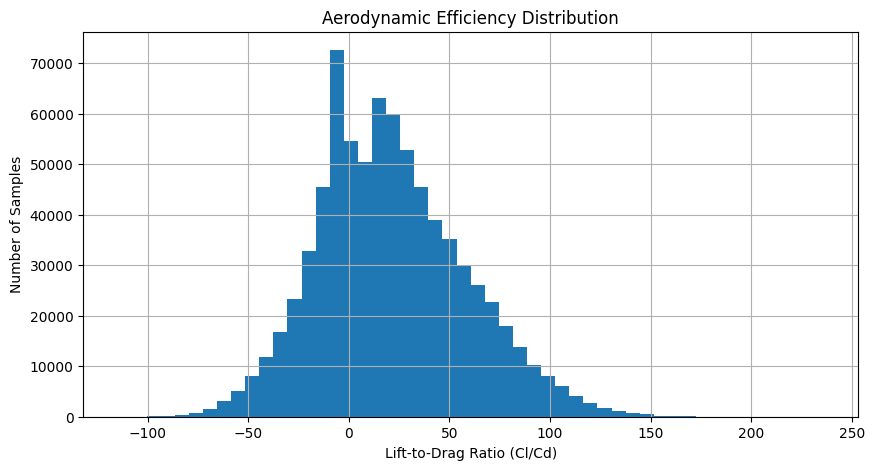

In [49]:
plt.figure(figsize=(10, 5))

plt.hist(
    df["Cl_Cd"].dropna(),
    bins=50
)

plt.xlabel("Lift-to-Drag Ratio (Cl/Cd)")
plt.ylabel("Number of Samples")

plt.title("Aerodynamic Efficiency Distribution")

plt.grid(True)

plt.show()

### Feature correlations

A Pearson correlation matrix over all numeric columns — this is a first, cheap look at which geometry
and flow-condition features move together with the aerodynamic targets (`Cl`, `Cd`, `Cm`), useful
groundwork before choosing model inputs or interpreting feature importance later.

In [50]:
numeric_df = df.select_dtypes(
    include=np.number
)

correlation = numeric_df.corr()

correlation.round(2)

,airfoil_id,max_thickness_percent,max_thickness_position,max_camber_percent,max_camber_position,Re,log_Re,alpha,Ncrit,Cl,Cd,Cm,Cl_Cd
airfoil_id,1.00,-0.04,0.11,-0.20,0.04,0.01,0.00,-0.02,0.01,-0.06,-0.05,0.12,-0.06
max_thickness_percent,-0.04,1.00,0.24,0.02,0.07,0.04,0.05,-0.07,0.03,-0.08,0.15,-0.04,-0.10
max_thickness_position,0.11,0.24,1.00,-0.41,0.14,0.00,0.00,-0.03,0.02,-0.14,-0.02,0.22,-0.11
max_camber_percent,-0.20,0.02,-0.41,1.00,0.25,-0.01,-0.01,0.09,-0.02,0.30,0.19,-0.67,0.24
max_camber_position,0.04,0.07,0.14,0.25,1.00,-0.00,-0.00,0.02,-0.00,0.10,0.04,-0.39,0.09
Re,0.01,0.04,0.00,-0.01,-0.00,1.00,0.91,0.01,0.01,0.05,-0.28,-0.10,0.19
log_Re,0.00,0.05,0.00,-0.01,-0.00,0.91,1.00,0.02,0.01,0.08,-0.35,-0.12,0.23
alpha,-0.02,-0.07,-0.03,0.09,0.02,0.01,0.02,1.00,0.00,0.93,0.12,0.18,0.58
Ncrit,0.01,0.03,0.02,-0.02,-0.00,0.01,0.01,0.00,1.00,-0.01,0.03,0.04,0.03
Cl,-0.06,-0.08,-0.14,0.30,0.10,0.05,0.08,0.93,-0.01,1.00,0.02,-0.10,0.75


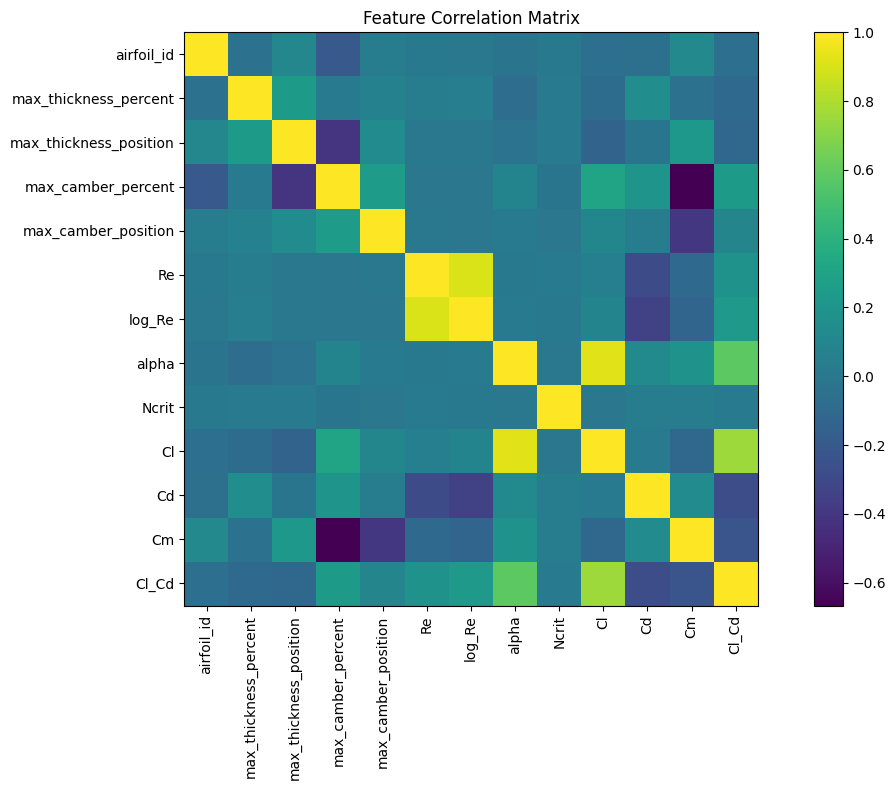

In [51]:
plt.figure(figsize=(12, 8))

plt.imshow(correlation)

plt.colorbar()

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Feature Correlation Matrix")

plt.tight_layout()

plt.show()

## Final summary

One last printout ties all three datasets together side by side — shapes, columns, a preview of each,
and Dataset A/C's descriptive statistics — as a final confirmation that Datasets A, B, and C are
consistent and ready to be used for the machine learning stage.

In [52]:
print("DATASET A")
print(metadata_df.shape)
print(metadata_df.columns.tolist())
print(metadata_df.head())
print(metadata_df.describe())

print("\nDATASET B")
print(aero_df.shape)
print(aero_df.columns.tolist())
print(aero_df.head())

print("\nDATASET C")
print(df.shape)
print(df.columns.tolist())
print(df.head())
print(df.describe())

DATASET A
(825, 12)
['airfoil_id', 'airfoil_name', 'source_file', 'pressure_points', 'suction_points', 'chord_length', 'max_thickness', 'max_thickness_percent', 'max_thickness_position', 'max_camber', 'max_camber_percent', 'max_camber_position']
   airfoil_id                                  airfoil_name  \
0           0                     2032c-il - 20-32C AIRFOIL   
1           1                       a18-il - A18 (original)   
2           2  a63a108c-il - NASA_AMES 63A108 MOD C AIRFOIL   
3           3                                ag04-il - AG04   
4           4                                ag09-il - AG09   

                                         source_file  pressure_points  \
0                     2032c-il - 20-32C AIRFOIL.json              100   
1                       a18-il - A18 (original).json              100   
2  a63a108c-il - NASA_AMES 63A108 MOD C AIRFOIL.json              100   
3                                ag04-il - AG04.json              100   
4         